 Generators and mutators: random genotypes and small changes to them

`FloatsGenerator` and `IntegersGenerator` draw random genotypes; `FloatMutator` and `IntegerMutator` make a child from a parent by changing some of its genes. All of them draw from one random generator that `seed` restarts, so a seeded run repeats exactly.

This notebook shows the shape of each sampler as a histogram, what each float mutator does to a straight line of genes, and what each integer mutator does to the numbers 0 to 19.

In [1]:
# third-party
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# local
from seachange import (
    FloatMutator,
    FloatsGenerator,
    IntegerMutator,
    IntegersGenerator,
    seed,
)

In [3]:
%matplotlib inline
plt.rcParams["figure.dpi"] = 72

# Chosen so every mutator below visibly changes its child
SEED = 19
DRAWS = 2_000
GENES = 20
PROBABILITY = 0.3
TOLERANCE = 0.1
ALWAYS = 1.0
CREEP = 2

seed(SEED)

# Seeding

`seed(n)` restarts every random draw seachange makes, so the same seed gives the same numbers.

In [4]:
seed(SEED)
first = FloatsGenerator.uniform(0, 1, size=3)
seed(SEED)
again = FloatsGenerator.uniform(0, 1, size=3)
print(first)
print(again)
assert list(first) == list(again)

[0.42037879572926085, 0.9258693448167037, 0.2738699878982821]
[0.42037879572926085, 0.9258693448167037, 0.2738699878982821]


# Samplers

2,000 draws from each sampler. Uniform floats fill their range evenly, normal ones bunch around the mean, lognormal ones are positive with a long right tail, and `integers(0, 5, endpoint=True)` gives each of 0 to 5 about one sixth of the draws.

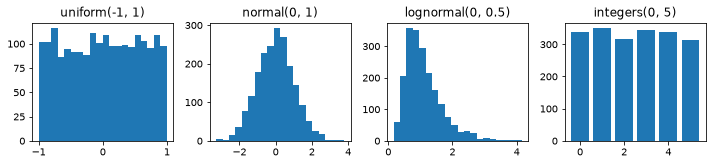

In [5]:
uniform = np.asarray(FloatsGenerator.uniform(-1, 1, size=DRAWS))
normal = np.asarray(FloatsGenerator.normal(0, 1, size=DRAWS))
lognormal = np.asarray(FloatsGenerator.lognormal(0, 0.5, size=DRAWS))
integers = np.asarray(
    IntegersGenerator.integers(0, 5, size=DRAWS, endpoint=True)
)

fig, axes = plt.subplots(1, 4, figsize=(10, 2.4))
axes[0].hist(uniform, bins=20)
axes[0].set_title("uniform(-1, 1)")
axes[1].hist(normal, bins=20)
axes[1].set_title("normal(0, 1)")
axes[2].hist(lognormal, bins=20)
axes[2].set_title("lognormal(0, 0.5)")
axes[3].hist(integers, bins=np.arange(-0.5, 6.5), rwidth=0.8)
axes[3].set_title("integers(0, 5)")
fig.tight_layout()
plt.show()

In [6]:
print(f"uniform   min {uniform.min():.3f}  max {uniform.max():.3f}")
print(f"normal    mean {normal.mean():.3f}  std {normal.std():.3f}")
print(f"lognormal min {lognormal.min():.3f}")
print(f"integers  {np.bincount(integers).tolist()}")
assert uniform.min() >= -1
assert uniform.max() <= 1
assert abs(normal.mean()) < TOLERANCE
assert lognormal.min() > 0
assert set(integers.tolist()) == set(range(6))

uniform   min -1.000  max 0.996
normal    mean 0.001  std 1.014
lognormal min 0.169
integers  [339, 350, 318, 343, 338, 312]


# Float mutators

Each mutator gets the same parent, 20 genes rising evenly from 0 to 1 (grey), and changes each gene with probability 0.3 (orange). `gaussian` adds noise, `uniform_reset` redraws a gene anywhere in the range, `boundary` moves it to an end of the range, `polynomial` nudges it within the range. `swap` and `inversion` keep the values and change their order. `inversion` reverses one stretch of genes, and its probability is the chance that it happens at all, not a chance per gene; it is 1 here so the change shows.

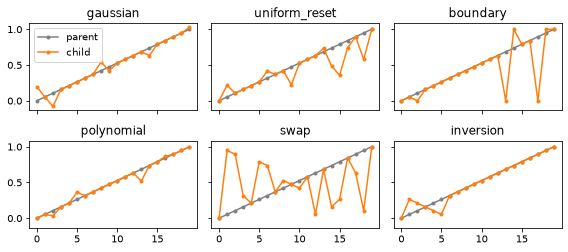

In [7]:
parent = np.linspace(0, 1, GENES).tolist()
float_children = {
    "gaussian": FloatMutator.gaussian(
        parent, std=0.1, mutation_probability=PROBABILITY
    ),
    "uniform_reset": FloatMutator.uniform_reset(parent, 0, 1, PROBABILITY),
    "boundary": FloatMutator.boundary(parent, 0, 1, PROBABILITY),
    "polynomial": FloatMutator.polynomial(parent, 0, 1, PROBABILITY),
    "swap": FloatMutator.swap(parent, PROBABILITY),
    "inversion": FloatMutator.inversion(parent, ALWAYS),
}
fig, axes = plt.subplots(2, 3, figsize=(8, 3.6), sharex=True, sharey=True)
for ax, (name, child) in zip(axes.flat, float_children.items(), strict=True):
    ax.plot(parent, color="grey", marker=".", label="parent")
    ax.plot(child, color="tab:orange", marker=".", label="child")
    ax.set_title(name)
axes[0, 0].legend(loc="upper left")
fig.tight_layout()
plt.show()

In [8]:
for name, child in float_children.items():
    changed = sum(a != b for a, b in zip(parent, child, strict=True))
    print(f"{name:<14} {changed:>2} of {GENES} genes changed")
assert set(float_children["boundary"]) <= {0.0, 1.0, *parent}
assert sorted(float_children["swap"]) == sorted(parent)
assert sorted(float_children["inversion"]) == sorted(parent)
assert all(0 <= gene <= 1 for gene in float_children["polynomial"])

gaussian        6 of 20 genes changed
uniform_reset   8 of 20 genes changed
boundary        5 of 20 genes changed
polynomial      4 of 20 genes changed
swap           12 of 20 genes changed
inversion       4 of 20 genes changed


# Integer mutators

The parent is 0 to 19 in order, so a changed gene stands out; a star marks each one. `random_reset` redraws a gene in 0 to 9, `integer_creep` moves it by at most 2 with no bounds (0 can become -1), and `swap`, `inversion` and `scramble` reorder the genes. As for floats, `inversion` and `scramble` act on one stretch with the given probability per child, here 1.

In [9]:
numbers = list(range(GENES))
integer_children = {
    "random_reset": IntegerMutator.random_reset(numbers, 0, 9, PROBABILITY),
    "integer_creep": IntegerMutator.integer_creep(numbers, CREEP, PROBABILITY),
    "swap": IntegerMutator.swap(numbers, PROBABILITY),
    "inversion": IntegerMutator.inversion(numbers, ALWAYS),
    "scramble": IntegerMutator.scramble(numbers, ALWAYS),
}
print(f"{'parent':<14}", "".join(f"{n:>3} " for n in numbers))
for name, child in integer_children.items():
    marks = (
        " " if c == n else "*" for c, n in zip(child, numbers, strict=True)
    )
    print(
        f"{name:<14}",
        "".join(f"{c:>3}{m}" for c, m in zip(child, marks, strict=False)),
    )

parent           0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19 
random_reset     6*  0*  0*  3   4   5   6   1*  8   9  10  11  12  13   4* 15   6* 17   9* 19 
integer_creep    0  -1*  0*  3   4   3*  8*  7   8   9  10  11  12  13  14  14* 16  17  17* 21*
swap             0  19* 10*  3   4   5   6   7  17*  1*  2* 11  12  13  14  15  16   8* 18   9*
inversion        0  12* 11* 10*  9*  8*  7*  6*  5*  4*  3*  2*  1* 13  14  15  16  17  18  19 
scramble         0   1   2   3  10* 14* 12*  8* 11* 15*  6*  7* 16* 13   5*  4*  9* 17  18  19 


In [10]:
creep = integer_children["integer_creep"]
assert all(abs(c - n) <= CREEP for c, n in zip(creep, numbers, strict=True))
for name in ("swap", "inversion", "scramble"):
    assert sorted(integer_children[name]) == numbers

`inversion` and `scramble` pick two cut points among the 21 gaps between genes. When the stretch between them is one or two genes long, the child can come back unchanged even though the mutation ran: for 20 genes, about one child in six.

In [11]:
unchanged = sum(
    IntegerMutator.scramble(numbers, ALWAYS) == numbers for _ in range(1_000)
)
print(f"scramble left {unchanged} of 1000 children unchanged")
assert unchanged < 1_000 / 4

scramble left 175 of 1000 children unchanged


# How many genes change

`mutation_probability` is the chance that each gene changes. Over 200 children of 20 genes, `gaussian` should change about that share of genes.

In [12]:
for probability in (0.1, 0.5, 0.9):
    changed = [
        sum(
            a != b
            for a, b in zip(
                parent,
                FloatMutator.gaussian(
                    parent, std=0.1, mutation_probability=probability
                ),
                strict=True,
            )
        )
        for _ in range(200)
    ]
    share = np.mean(changed) / GENES
    print(f"probability {probability}: {share:.3f} of genes changed")
    assert abs(share - probability) < TOLERANCE

probability 0.1: 0.096 of genes changed
probability 0.5: 0.503 of genes changed
probability 0.9: 0.903 of genes changed
